# A Transformer-Based Approach for Raw EEG Classification

### 1. Setup and Imports

Import necessary libraries and set up the environment.



In [1]:
%load_ext autoreload
%autoreload 2 
#%autoreload 2 fa in modo che, ogni volta che modifichi e salvi un file .py, Jupyter ricarichi automaticamente le modifiche nel notebook senza chiederti di riavviare il kernel!†

In [3]:
import numpy as np
from pathlib import Path
import re
import sys

src_path = Path('../src/eeg-bci-transformer-pipeline').resolve()
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))
#from datapreprocessing import EEGpreprocessing, EEGDataset
from articolodatapreprocessing import EEGpreprocessing, EEGDataset
from train import EarlyStopper, EEGTrainer
from rozzotrain import EarlyStopper, EEGTrainer
#from models import ScaledDotProductAttention, MultiHeadAttention, FeedForward, TransformerLayer, ConvolutionModule, EEGConformer, EEGTransformerConv1D
from models import ScaledDotProductAttention, MultiHeadAttention, FeedForward, TransformerLayer, SpatialCNN, TemporalCNN, PositionalEncoding,  F_CTrans


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import mne
import os
from sklearn.model_selection import KFold,GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Configuration and Hyperparameters

Define all model and training parameters

### 3. Data Loading and Preprocessing

Load the PhysioNet EEG Motor Movement/Imagery Dataset 

In [4]:
CURRENT_DIR = Path.cwd()

DATASET_PATH = (CURRENT_DIR.parent / "data" / "MotorImagery(04,08,012)") if CURRENT_DIR.name == "notebook" else (CURRENT_DIR / "data" / "MotorImagery(04,08,012)")

print(f"Percorso dataset utilizzato: {DATASET_PATH}")

edf_files = sorted(DATASET_PATH.glob("**/*.edf"))

file_records = []
for edf_path in edf_files:
    filename = edf_path.stem
    match = re.search(r'S(\d+)', filename, re.IGNORECASE)
    if match:
        subj_id = int(match.group(1))
        file_records.append({'path': edf_path, 'subject_id': subj_id})

file_subject_ids = np.array([r['subject_id'] for r in file_records])
unique_subjects = np.unique(file_subject_ids)

# Split riproducibile sui SOGGETTI (Test set isolato)
np.random.seed(42)
shuffled_subjects = unique_subjects.copy()
np.random.shuffle(shuffled_subjects)

test_subjects = set(shuffled_subjects[:11])
train_val_subjects = set(shuffled_subjects[11:])

train_val_records = [r for r in file_records if r['subject_id'] in train_val_subjects]
test_records = [r for r in file_records if r['subject_id'] in test_subjects]

print(f"File EDF for Train/Validation: {len(train_val_records)}")
print(f"File EDF for TEST: {len(test_records)}")


Percorso dataset utilizzato: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)
File EDF for Train/Validation: 294
File EDF for TEST: 33


Apply preprocessing  #momontaneamente lo faccio solo sul train/val perchè non sono sicura vada fatto sul test, riparlarne con luca

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import mne

#Faccio 3s 
# Liste di accumulo per i dati finali
X_raw_list = []
y_list = []
subject_ids_list = []
psd_records = []  

for i, rec in enumerate(train_val_records):
    file_path = rec['path']
    subj_id = rec['subject_id']

    print(f"Elaborazione Soggetto {subj_id} - File: {file_path}")

    # 1. Caricamento del file raw EDF specificando encoding='latin1' per evitare il UnicodeDecodeError
    try:
        raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1')
    except Exception as e:
        print(f"❌ ERRORE: Impossibile leggere il file del Soggetto {subj_id}!")
        print(f"   Percorso: {file_path}")
        print(f"   Dettaglio: {e}")
        continue

    # 2. Applicazione della pipeline di preprocessing (Filtro e Epoching a 3s)
    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=8.0, h_freq=30.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=3.0)

    # 3. Controllo di sicurezza: se non ci sono epoche, saltiamo
    if len(epochs_mne) == 0:
        print(f"⚠️ Attenzione: Nessuna epoca trovata per il Soggetto {subj_id}. Salto.")
        continue
    
    # 4. Calcolo della PSD sulle epoche valide
    psd_object = epochs_mne.compute_psd(fmin=1, fmax=40, method='welch', verbose=False)
    psd_values, freqs = psd_object.get_data(return_freqs=True) 
    
    psd_records.append({
        'subject_id': subj_id,
        'frequencies': freqs,
        'psd_data': psd_values,
        'mean_power_per_channel': np.mean(psd_values, axis=(0, 2))
    })

    # 5. Estrazione dei dati grezzi delle epoche per il modello
    X_raw = epochs_mne.get_data(copy=True) # Shape: (n_trials, 64, 480)

    # Estrazione e mappatura delle etichette (Left = 0, Right = 1)
    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    
    labels = np.zeros(len(y), dtype=np.int64)
    if 'Left' in event_id and event_id['Left'] in y:
        labels[y == event_id['Left']] = 0
    if 'Right' in event_id and event_id['Right'] in y:
        labels[y == event_id['Right']] = 1

    # Accumulo nelle liste globali
    X_raw_list.append(X_raw)
    y_list.append(labels)
    subject_ids_list.extend([subj_id] * len(X_raw))

print("\n✨ Ciclo di estrazione completato con successo!")
print(f"Soggetti elaborati correttamente: {len(X_raw_list)}")

Elaborazione Soggetto 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 481 original time points ...
0 bad epochs dropped
Elaborazione Soggetto 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 481 original time points ...
0 bad epochs dropped
Elaborazione Soggetto 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R12.edf
Used Annotations descriptions: ['T0', 'T1'

/tmp/ipykernel_55886/2665548533.py:20: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1')


Elaborazione Soggetto 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
10 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 10 events and 481 original time points ...
0 bad epochs dropped
Elaborazione Soggetto 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 481 original time points ...
0 bad epochs dropped


/tmp/ipykernel_55886/2665548533.py:20: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1')


Elaborazione Soggetto 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 481 original time points ...
0 bad epochs dropped
Elaborazione Soggetto 36 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S036/S036R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 481 original time points ...
0 bad epochs dropped
Elaborazione Soggetto 36 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S036/S036R08.edf
Used Annotations descriptions: ['T0', '

...

Elaborazione Soggetto 86 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S086/S086R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 481 original time points ...
0 bad epochs dropped
Elaborazione Soggetto 86 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S086/S086R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 481 original time points ...
0 bad epochs dropped
Elaborazione Soggetto 87 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S087/S087R04.edf
Used Annotations descriptions: ['T0', '

/tmp/ipykernel_55886/2665548533.py:20: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1')
/tmp/ipykernel_55886/2665548533.py:20: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1')


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 481 original time points ...
0 bad epochs dropped
Elaborazione Soggetto 100 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S100/S100R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 481 original time points ...
0 bad epochs dropped
Elaborazione Soggetto 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R04.edf


/tmp/ipykernel_55886/2665548533.py:20: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1')


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 481 original time points ...
0 bad epochs dropped
Elaborazione Soggetto 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 481 original time points ...
0 bad epochs dropped
Elaborazione Soggetto 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw fo

In [6]:
'''
for i, record in enumerate(psd_records[:4]):
    print(f"--- Paziente {i+1} ---")
    print(f"Subject ID: {record['subject_id']}")
    print(f"Shape della PSD (epoche, canali, frequenze): {record['psd_data'].shape}")
    print(f"Potenza media per canale (primi 5 canali): {record['mean_power_per_channel'][:63]}")
    print("-" * 30)
'''

'\nfor i, record in enumerate(psd_records[:4]):\n    print(f"--- Paziente {i+1} ---")\n    print(f"Subject ID: {record[\'subject_id\']}")\n    print(f"Shape della PSD (epoche, canali, frequenze): {record[\'psd_data\'].shape}")\n    print(f"Potenza media per canale (primi 5 canali): {record[\'mean_power_per_channel\'][:63]}")\n    print("-" * 30)\n'

Convert to PyTorch tensors

In [6]:
X_training_validation_raw = np.concatenate(X_raw_list, axis=0)
y_training_validation = np.concatenate(y_list, axis=0)
subjects_ids_training_validation = np.array(subject_ids_list)

print(f"Dimensioni X_train_val grezzo: {X_training_validation_raw.shape}")
print(f"Dimensioni y_train_val: {y_training_validation.shape}")
print("Distribuzione etichette:", np.unique(y_training_validation, return_counts=True))

Dimensioni X_train_val grezzo: (4388, 64, 481)
Dimensioni y_train_val: (4388,)
Distribuzione etichette: (array([0, 1]), array([2214, 2174]))


In [7]:
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)


### Cross-Individual 3-Fold Cross-Validation and Random grid search to tuning hyperparameters

PROVO fctrans

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 ---
Controllo rapido del batch di training...
Forma batch input: torch.Size([64, 64, 481]) (Atteso: [Batch, 64, 641])
Forma batch labels: torch.Size([64]) (Atteso: [Batch])
Tipo dati labels: torch.int64 (Atteso: torch.int64)
Forma output modello: torch.Size([64, 2]) (Atteso: [Batch, 2])
Diagnostica superata con successo! Avvio le epoche...

Epoch 01/50: train_loss=0.74126, val_loss=0.69688, val_acc=48.93%
Epoch 02/50: train_loss=0.69550, val_loss=0.69398, val_acc=48.93%
Epoch 03/50: train_loss=0.69703, val_loss=0.69284, val_acc=51.07%
Epoch 04/50: train_loss=0.69382, val_loss=0.75578, val_acc=48.93%
Epoch 05/50: train_loss=0.69763, val_loss=0.69299, val_acc=51.07%
Epoch 06/50: train_loss=0.69495, val_loss=0.69280, val_acc=51.07%
Epoch 07/50: train_loss=0.69790, val_loss=0.69905, val_acc=51.07%
Epoch 08/50: train_loss=0.69481, val_loss=0.69327, val_acc=51.07%
Epoch 09/50: train_loss=0.69463, val_loss

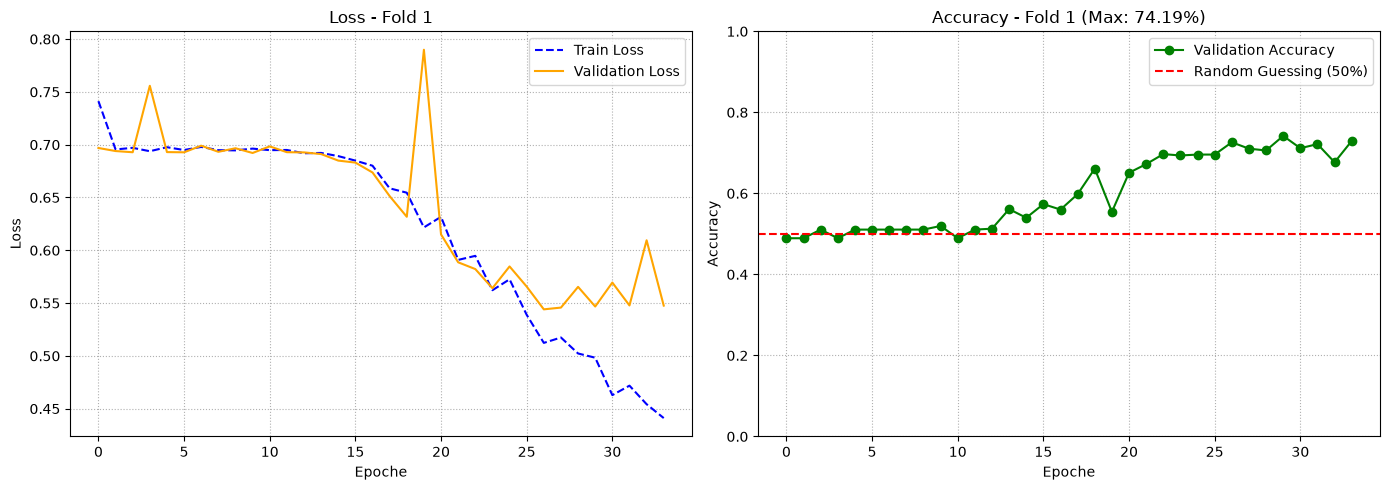


--- INIZIO TRAINING & VALIDAZIONE - FOLD 2/5 ---
Controllo rapido del batch di training...
Forma batch input: torch.Size([64, 64, 481]) (Atteso: [Batch, 64, 641])
Forma batch labels: torch.Size([64]) (Atteso: [Batch])
Tipo dati labels: torch.int64 (Atteso: torch.int64)
Forma output modello: torch.Size([64, 2]) (Atteso: [Batch, 2])
Diagnostica superata con successo! Avvio le epoche...

Epoch 01/50: train_loss=0.74074, val_loss=0.69452, val_acc=49.48%
Epoch 02/50: train_loss=0.69475, val_loss=0.70093, val_acc=49.48%
Epoch 03/50: train_loss=0.69701, val_loss=0.70973, val_acc=49.48%
Epoch 04/50: train_loss=0.69748, val_loss=0.69805, val_acc=50.52%
Epoch 05/50: train_loss=0.69622, val_loss=0.69569, val_acc=49.48%
Epoch 06/50: train_loss=0.69587, val_loss=0.69440, val_acc=50.52%
Epoch 07/50: train_loss=0.69726, val_loss=0.70035, val_acc=49.48%
Epoch 08/50: train_loss=0.69375, val_loss=0.69775, val_acc=49.48%
Epoch 09/50: train_loss=0.69515, val_loss=0.69284, val_acc=50.52%
Epoch 10/50: trai

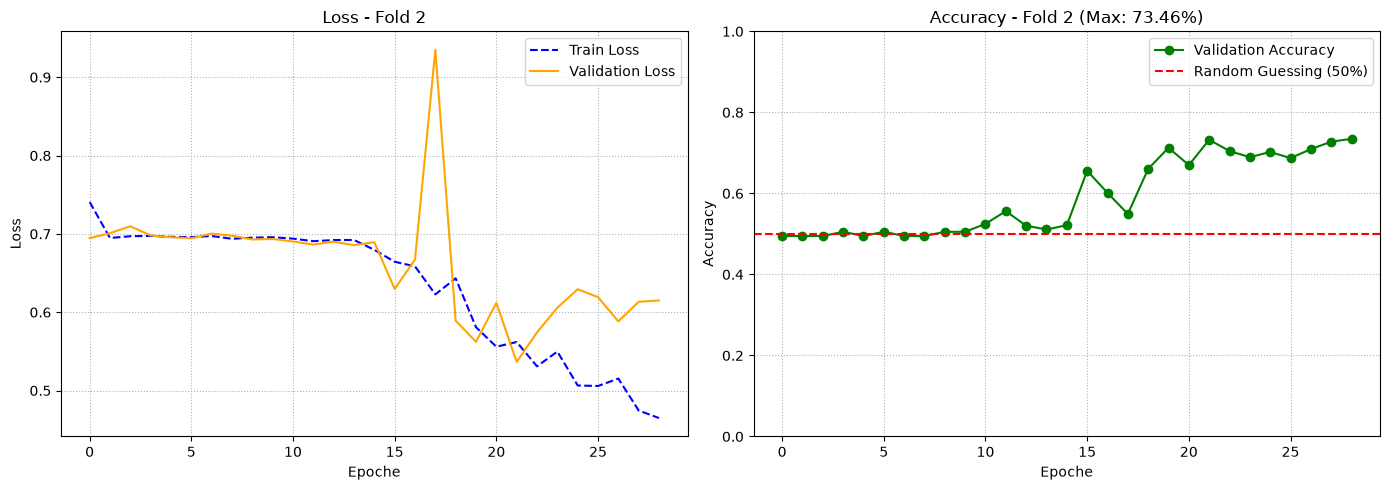


--- INIZIO TRAINING & VALIDAZIONE - FOLD 3/5 ---
Controllo rapido del batch di training...
Forma batch input: torch.Size([64, 64, 481]) (Atteso: [Batch, 64, 641])
Forma batch labels: torch.Size([64]) (Atteso: [Batch])
Tipo dati labels: torch.int64 (Atteso: torch.int64)
Forma output modello: torch.Size([64, 2]) (Atteso: [Batch, 2])
Diagnostica superata con successo! Avvio le epoche...

Epoch 01/50: train_loss=0.75071, val_loss=0.69568, val_acc=49.65%
Epoch 02/50: train_loss=0.69644, val_loss=0.69786, val_acc=49.65%
Epoch 03/50: train_loss=0.69905, val_loss=0.69336, val_acc=50.35%
Epoch 04/50: train_loss=0.69810, val_loss=0.69564, val_acc=49.65%
Epoch 05/50: train_loss=0.69366, val_loss=0.70075, val_acc=49.65%
Epoch 06/50: train_loss=0.69852, val_loss=0.69307, val_acc=49.65%
Epoch 07/50: train_loss=0.70018, val_loss=0.69936, val_acc=49.65%
Epoch 08/50: train_loss=0.69646, val_loss=0.69525, val_acc=49.65%
Epoch 09/50: train_loss=0.69590, val_loss=0.69286, val_acc=50.35%
Epoch 10/50: trai

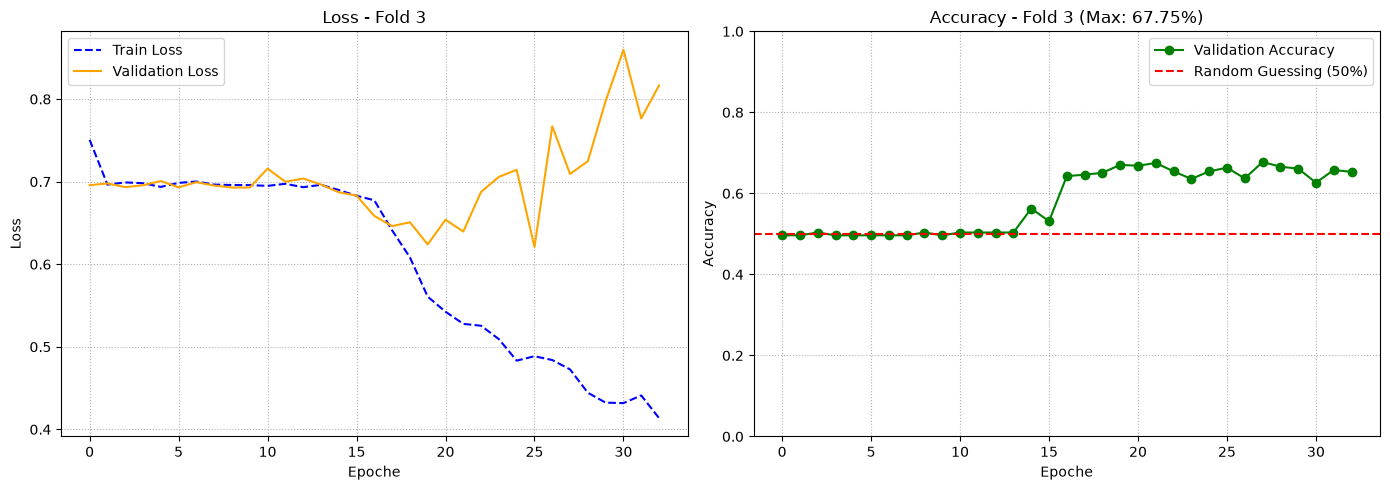


--- INIZIO TRAINING & VALIDAZIONE - FOLD 4/5 ---
Controllo rapido del batch di training...
Forma batch input: torch.Size([64, 64, 481]) (Atteso: [Batch, 64, 641])
Forma batch labels: torch.Size([64]) (Atteso: [Batch])
Tipo dati labels: torch.int64 (Atteso: torch.int64)
Forma output modello: torch.Size([64, 2]) (Atteso: [Batch, 2])
Diagnostica superata con successo! Avvio le epoche...

Epoch 01/50: train_loss=0.73149, val_loss=0.70853, val_acc=49.89%
Epoch 02/50: train_loss=0.70088, val_loss=0.69415, val_acc=49.89%
Epoch 03/50: train_loss=0.69381, val_loss=0.70659, val_acc=49.89%
Epoch 04/50: train_loss=0.70040, val_loss=0.69383, val_acc=50.11%
Epoch 05/50: train_loss=0.69453, val_loss=0.69768, val_acc=49.89%
Epoch 06/50: train_loss=0.70477, val_loss=0.70699, val_acc=50.11%
Epoch 07/50: train_loss=0.69558, val_loss=0.69758, val_acc=49.89%
Epoch 08/50: train_loss=0.69772, val_loss=0.69281, val_acc=51.69%
Epoch 09/50: train_loss=0.69430, val_loss=0.69585, val_acc=50.11%
Epoch 10/50: trai

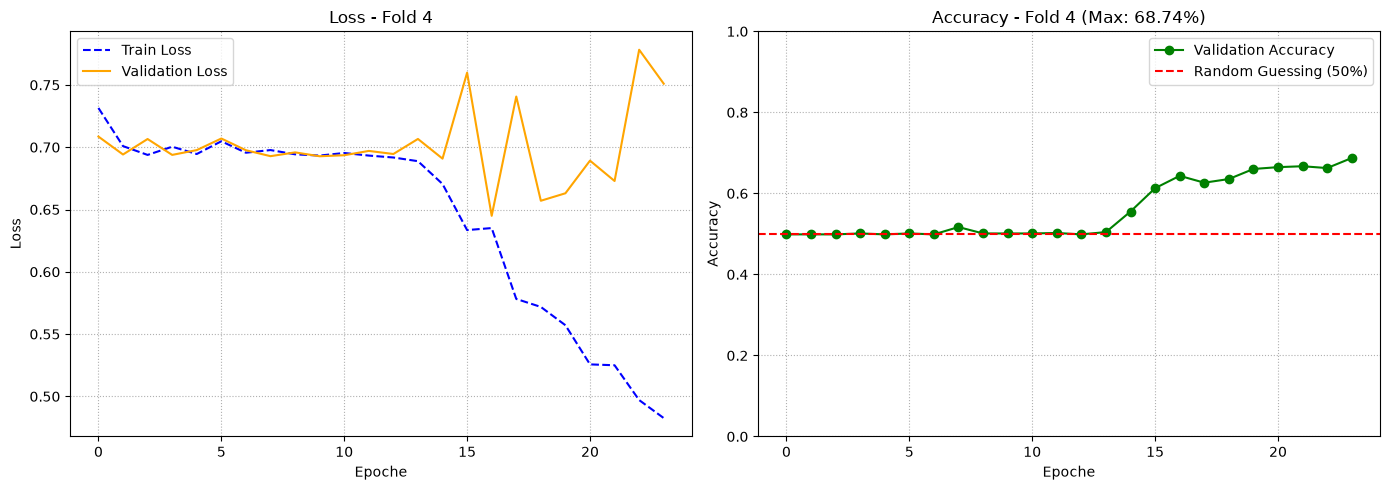


--- INIZIO TRAINING & VALIDAZIONE - FOLD 5/5 ---
Controllo rapido del batch di training...
Forma batch input: torch.Size([64, 64, 481]) (Atteso: [Batch, 64, 641])
Forma batch labels: torch.Size([64]) (Atteso: [Batch])
Tipo dati labels: torch.int64 (Atteso: torch.int64)
Forma output modello: torch.Size([64, 2]) (Atteso: [Batch, 2])
Diagnostica superata con successo! Avvio le epoche...

Epoch 01/50: train_loss=0.75558, val_loss=0.69361, val_acc=49.77%
Epoch 02/50: train_loss=0.70369, val_loss=0.69326, val_acc=49.77%
Epoch 03/50: train_loss=0.69701, val_loss=0.69537, val_acc=50.23%
Epoch 04/50: train_loss=0.69745, val_loss=0.69514, val_acc=49.77%
Epoch 05/50: train_loss=0.69494, val_loss=0.69346, val_acc=49.77%
Epoch 06/50: train_loss=0.69518, val_loss=0.69446, val_acc=50.23%
Epoch 07/50: train_loss=0.69477, val_loss=0.69321, val_acc=50.11%
Epoch 08/50: train_loss=0.69603, val_loss=0.69677, val_acc=49.77%
Epoch 09/50: train_loss=0.69607, val_loss=0.69409, val_acc=50.23%
Epoch 10/50: trai

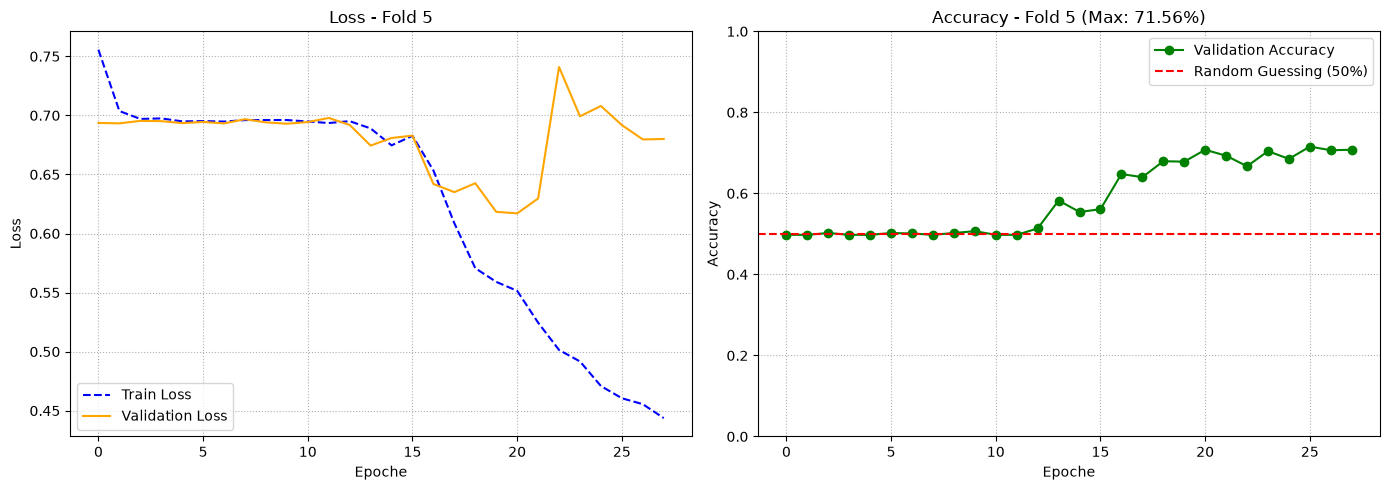


🎉 TRAINING COMPLETATO SU TUTTI I FOLD!
📊 Accuracy media cross-validation: 71.14% (± 2.54%)


In [23]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")



# 2. Parametri di Configurazione Ottimizzati
BATCH_SIZE = 64        # Ridotto a 32 per stabilizzare i gradienti sui Transformer EEG
EPOCHS = 50            # Leggermente aumentate, ci pensa l'Early Stopping a fermare tutto
LR = 0.001        # Learning rate leggermente più prudente per il Transformer
WEIGHT_DECAY = 0.1   # Strong weight decay per regolarizzare contro l'overfitting
ALPHA_NOISE = 0.01     # Intensità del rumore di augmentation
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)

# Liste per raccogliere le metriche di tutti i fold
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

# ==========================================
# 3. CICLO DI TRAINING CON GROUPKFOLD
# ==========================================
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 ---")

    # A. Split dei dati grezzi
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set (Prevenzione Data Leakage)
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    


    # F. Inizializzazione del Modello 
    # NOTA: Assicurati che d_model corrisponda ai canali in uscita del CNN module o gestiscilo con una Linear layer.
    model = F_CTrans(num_channels = 64 ,d_model= 64, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
   
    # G. Ottimizzatore, Loss e Scheduler
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
  
    # H. Trainer personalizzato
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )

    print("Controllo rapido del batch di training...")
    for inputs, labels in train_loader:
        print(f"Forma batch input: {inputs.shape} (Atteso: [Batch, 64, 641])")
        print(f"Forma batch labels: {labels.shape} (Atteso: [Batch])")
        print(f"Tipo dati labels: {labels.dtype} (Atteso: torch.int64)")
        
        # Test di forward pass per verificare che non ci siano crash di shape
        outputs, _ = model(inputs.to(device))
        print(f"Forma output modello: {outputs.shape} (Atteso: [Batch, 2])")
        break
    print("Diagnostica superata con successo! Avvio le epoche...\n")

    # I. Training e Validazione con Early Stopping integrato
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS
    )

    fold_accuracies.append(best_val_acc)
    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc*100:.2f}%")

    # Salvataggio del modello migliore assoluto
    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY
    # ==========================================
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    
print(f"\n🎉 TRAINING COMPLETATO SU TUTTI I FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

grid search

In [26]:
from sklearn.model_selection import GroupKFold
import itertools
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# 1. Definizione della Grid dei Parametri
param_grid = {
    'lr': [1e-3, 1e-4],
    'dropout': [0.3, 0.5],
    'weight_decay': [1e-3, 1e-2]
}

EPOCHS = 30
N_SPLITS = 3  # Puoi metterlo a 3 per la Grid Search e a 5 per il test finale

# Inizializziamo il GroupKFold
gkf = GroupKFold(n_splits=N_SPLITS)

# Generiamo tutte le combinazioni possibili
keys = param_grid.keys()
values = param_grid.values()
param_combinations = [dict(zip(keys, combination)) for combination in itertools.product(*values)]

best_overall_acc = 0.0
best_params = None

print(f"🚀 Avvio Grid Search con GroupKFold (K={N_SPLITS}): {len(param_combinations)} combinazioni totali.\n")

for i, params in enumerate(param_combinations, 1):
    print(f"\n==========================================")
    print(f"--- COMBINAZIONE {i}/{len(param_combinations)} ---")
    print(f"Parametri: {params}")
    print(f"==========================================")
    
    comb_fold_accs = []
    comb_fold_losses = []
    
    # 2. Ciclo di Cross-Validation basato sui gruppi (Soggetti)
    # NOTA: Passiamo groups a gkf.split(X, y, groups)
    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
        print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold}/{N_SPLITS} ---")
    
        # A. Split dei dati grezzi rispettando i gruppi
        X_train_raw = X_training_validation_raw[train_idx]
        y_train = y_training_validation[train_idx]
        
        X_val_raw = X_training_validation_raw[val_idx]
        y_val = y_training_validation[val_idx]
        
        # B. Calcolo Media e Std rigorosamente sul Training Set del gruppo corrente (Zero Data Leakage)
        train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
        train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
        epsilon = 1e-8
    
        # C. Normalizzazione + Data Augmentation sul Train
        X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
        noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
        X_train_final = X_train_norm + noise
    
        # D. Normalizzazione pura sul Validation Set (usando le metriche del Train)
        X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)
    
        # E. Dataset e DataLoader PyTorch
        train_dataset = EEGDataset(X_train_final, y_train)
        val_dataset = EEGDataset(X_val_final, y_val)
    
        train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

        # F. Modello
        model = F_CTrans(
            num_channels=64, 
            d_model=64, 
            nhead=8, 
            d_ff=512, 
            dropout=params['dropout'], 
            num_layers=3, 
            num_classes=2
        ).to(device)
    
        # G. Ottimizzatore e Scheduler
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.AdamW(model.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, 
            mode='min', 
            factor=0.5, 
            patience=3, 
            min_lr=1e-6
        )
    
        # H. Trainer
        trainer = EEGTrainer(
            model=model, 
            criterion=criterion, 
            optimizer=optimizer,  
            device=device
        )
        trainer.scheduler = scheduler

        # I. Training Loop
        best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate_con(
            train_loader=train_loader, 
            val_loader=val_loader, 
            epochs=EPOCHS,
            scheduler=scheduler
        )
        
        max_fold_acc = max(val_accuracies)
        min_fold_loss = min(val_losses)

        comb_fold_accs.append(max_fold_acc)
        comb_fold_losses.append(min_fold_loss)

        print(f"✅ Fold {fold} completato | Min Val Loss: {min_fold_loss:.4f} | Max Val Acc: {max_fold_acc*100:.2f}%")

    # Calcolo della media sui fold per questa combinazione di iperparametri
    mean_comb_acc = np.mean(comb_fold_accs)
    mean_comb_loss = np.mean(comb_fold_losses)
    print(f"\n📊 Combinazione {i} Completata -> Acc Media (Cross-Subject): {mean_comb_acc*100:.2f}% | Loss Media: {mean_comb_loss:.4f}")

    if mean_comb_acc > best_overall_acc:
        best_overall_acc = mean_comb_acc
        best_params = params

print(f"\n==========================================")
print(f"🏆 GRID SEARCH CROSS-SUBJECT COMPLETATA")
print(f"==========================================")
print(f"Migliori Parametri Trovati: {best_params}")
print(f"Migliore Validation Accuracy Media: {best_overall_acc * 100:.2f}%")

🚀 Avvio Grid Search con GroupKFold (K=3): 8 combinazioni totali.


--- COMBINAZIONE 1/8 ---
Parametri: {'lr': 0.001, 'dropout': 0.3, 'weight_decay': 0.001}

--- INIZIO TRAINING & VALIDAZIONE - FOLD 0/3 ---
Epoch 01/30: train_loss=0.77461, val_loss=0.69309, val_acc=50.41%
Epoch 02/30: train_loss=0.69672, val_loss=0.70073, val_acc=50.54%
Epoch 03/30: train_loss=0.70337, val_loss=0.69735, val_acc=49.46%
Epoch 04/30: train_loss=0.69709, val_loss=0.69447, val_acc=49.46%
Epoch 05/30: train_loss=0.69733, val_loss=0.69557, val_acc=49.46%
Epoch 06/30: train_loss=0.69477, val_loss=0.69322, val_acc=50.54%
Epoch 07/30: train_loss=0.70169, val_loss=0.70923, val_acc=50.54%
Epoch 08/30: train_loss=0.69780, val_loss=0.69924, val_acc=49.46%
Early stopping all'epoca 8
✅ Fold 0 completato | Min Val Loss: 0.6931 | Max Val Acc: 50.54%

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/3 ---
Epoch 01/30: train_loss=0.75192, val_loss=0.69323, val_acc=49.83%
Epoch 02/30: train_loss=0.69476, val_loss=0.69317, val_acc

KeyboardInterrupt: 

In [ ]:
from sklearn.model_selection import GroupKFold
import itertools
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# 1. Definizione della Grid dei Parametri
param_grid = {
    'lr': [1e-3, 1e-4],
    'dropout': [0.3, 0.5],
    'weight_decay': [1e-3, 1e-2]
}

EPOCHS = 30
N_SPLITS = 3  # Puoi metterlo a 3 per la Grid Search e a 5 per il test finale

# Inizializziamo il GroupKFold
gkf = GroupKFold(n_splits=N_SPLITS)

# Generiamo tutte le combinazioni possibili
keys = param_grid.keys()
values = param_grid.values()
param_combinations = [dict(zip(keys, combination)) for combination in itertools.product(*values)]

best_overall_acc = 0.0
best_params = None

print(f"🚀 Avvio Grid Search con GroupKFold (K={N_SPLITS}): {len(param_combinations)} combinazioni totali.\n")

for i, params in enumerate(param_combinations, 1):
    print(f"\n==========================================")
    print(f"--- COMBINAZIONE {i}/{len(param_combinations)} ---")
    print(f"Parametri: {params}")
    print(f"==========================================")
    
    comb_fold_accs = []
    comb_fold_losses = []
    
    # 2. Ciclo di Cross-Validation basato sui gruppi (Soggetti)
    # NOTA: Passiamo groups a gkf.split(X, y, groups)
    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
        print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold}/{N_SPLITS} ---")
    
        # A. Split dei dati grezzi rispettando i gruppi
        X_train_raw = X_training_validation_raw[train_idx]
        y_train = y_training_validation[train_idx]
        
        X_val_raw = X_training_validation_raw[val_idx]
        y_val = y_training_validation[val_idx]
        
        # B. Calcolo Media e Std rigorosamente sul Training Set del gruppo corrente (Zero Data Leakage)
        train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
        train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
        epsilon = 1e-8
    
        # C. Normalizzazione + Data Augmentation sul Train
        X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
        noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
        X_train_final = X_train_norm + noise
    
        # D. Normalizzazione pura sul Validation Set (usando le metriche del Train)
        X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)
    
        # E. Dataset e DataLoader PyTorch
        train_dataset = EEGDataset(X_train_final, y_train)
        val_dataset = EEGDataset(X_val_final, y_val)
    
        train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

        # F. Modello
        model = F_CTrans(
            num_channels=64, 
            d_model=64, 
            nhead=8, 
            d_ff=512, 
            dropout=params['dropout'], 
            num_layers=3, 
            num_classes=2
        ).to(device)
    
        # G. Ottimizzatore e Scheduler
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.AdamW(model.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
        
    
        # H. Trainer
        trainer = EEGTrainer(
            model=model, 
            criterion=criterion, 
            optimizer=optimizer,  
            device=device
        )
        trainer.scheduler = scheduler

        # I. Training Loop
        best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
            train_loader=train_loader, 
            val_loader=val_loader, 
            epochs=EPOCHS
        )
        
        max_fold_acc = max(val_accuracies)
        min_fold_loss = min(val_losses)

        comb_fold_accs.append(max_fold_acc)
        comb_fold_losses.append(min_fold_loss)

        print(f"✅ Fold {fold} completato | Min Val Loss: {min_fold_loss:.4f} | Max Val Acc: {max_fold_acc*100:.2f}%")

    # Calcolo della media sui fold per questa combinazione di iperparametri
    mean_comb_acc = np.mean(comb_fold_accs)
    mean_comb_loss = np.mean(comb_fold_losses)
    print(f"\n📊 Combinazione {i} Completata -> Acc Media (Cross-Subject): {mean_comb_acc*100:.2f}% | Loss Media: {mean_comb_loss:.4f}")

    if mean_comb_acc > best_overall_acc:
        best_overall_acc = mean_comb_acc
        best_params = params

print(f"\n==========================================")
print(f"🏆 GRID SEARCH CROSS-SUBJECT COMPLETATA")
print(f"==========================================")
print(f"Migliori Parametri Trovati: {best_params}")
print(f"Migliore Validation Accuracy Media: {best_overall_acc * 100:.2f}%")